# Imagens do CBIS-DDSM: qualidade, calcificações e viés

Etapa complementar do trabalho. A análise exploratória (`01_analise_exploratoria.ipynb`) comparou os **metadados**
do CBIS-DDSM com o Brasil. Aqui olhamos as **imagens**:

1. **Ligação e qualidade:** cada lesão tem suas imagens? Os rótulos das imagens estão certos?
2. **Validação visual:** mamografia, máscara e recorte batem entre si?
3. **PDI:** realce e segmentação de microcalcificações, e extração de características;
4. **Características × malignidade e × densidade mamária;**
5. **Modelo simples e viés:** como o desempenho muda por densidade e com a prevalência de câncer do SUS.

As imagens (~6 GB, versão JPEG do Kaggle) ficam em `data/raw/cbis-ddsm/jpeg/`; ver o README.

In [1]:
import sys
sys.path.append("..")

import cv2
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy.stats import kruskal, mannwhitneyu
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

from src import config
from src.images import calcificacoes as calc_pdi
from src.images.calcificacoes import extrai_caracteristicas, fracao_binaria, le_cinza
from src.processing.cbis import carrega_cbis, carrega_imagens, liga_imagens
from src.visualization import estilo
from src.visualization.estilo import AZUL, LARANJA, VERDE_AGUA, salvar

estilo.aplicar()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

lesoes = carrega_cbis()
lesoes["breast_density"] = lesoes["breast_density"].replace(0, np.nan)
imagens = carrega_imagens()
print(f"{len(lesoes)} lesões, {len(imagens)} imagens, {imagens['existe'].sum()} arquivos encontrados")

3568 lesões, 10237 imagens, 10237 arquivos encontrados


## 1. Ligação imagens ↔ lesões e controle de qualidade

Cada linha de lesão aponta para 3 imagens: a **mamografia completa**, o **recorte** (crop) da lesão e a **máscara**
(ROI) que marca a lesão na mamografia. O `dicom_info.csv` informa o tipo de cada imagem em `SeriesDescription`.

In [2]:
ligado = liga_imagens(lesoes, imagens)
cobertura = pd.DataFrame({
    tipo: [ligado[f"caminho_{tipo}"].notna().sum(), 100 * ligado[f"caminho_{tipo}"].notna().mean()]
    for tipo in ["full", "recorte", "mascara"]
}, index=["lesões com imagem", "%"]).T
print("Imagens sem tipo (SeriesDescription vazio):", imagens["tipo_imagem"].isna().sum())
cobertura

Imagens sem tipo (SeriesDescription vazio): 566


,lesões com imagem,%
full,"3,286.000",92.096
recorte,"3,567.000",99.972
mascara,"3,247.000",91.003


### 1.1 Imagens sem tipo

As imagens sem `SeriesDescription` têm outro formato de identificador (ex.: `P_00562_LEFT_CC_2.dcm`, sem o
prefixo `Calc-`/`Mass-`) e tamanho de mamografia inteira. Hipótese: são as **máscaras** que faltam (≈ 9% das lesões
estão sem máscara). Uma máscara é quase toda preta ou branca. Então a **fração de pixels binários** decide o tipo
pelo **conteúdo**. Para ser rápido, o JPEG é decodificado já reduzido 8×.

O mesmo teste verifica se há recortes e máscaras **trocados**, um problema conhecido dessa versão do dataset:
um recorte "binário" seria, na verdade, uma máscara.

In [3]:
cache_qualidade = config.INTERIM / "cbis_qualidade_imagens.csv"
if cache_qualidade.exists():
    qualidade = pd.read_csv(cache_qualidade)
else:
    alvo = imagens[imagens["tipo_imagem"].isin(["cropped images", "ROI mask images"]) | imagens["tipo_imagem"].isna()]
    qualidade = alvo[["case_id", "tipo_imagem", "caminho"]].copy()
    qualidade["fracao_binaria"] = [
        fracao_binaria(le_cinza(c, reducao=1 if t == "cropped images" else 8))
        for c, t in zip(qualidade["caminho"], qualidade["tipo_imagem"])
    ]
    qualidade.to_csv(cache_qualidade, index=False)

qualidade["tipo_rotulado"] = qualidade["tipo_imagem"].fillna("sem tipo")
qualidade.groupby("tipo_rotulado")["fracao_binaria"].describe(percentiles=[0.01, 0.5, 0.99])

,count,mean,std,min,1%,50%,99%,max
tipo_rotulado,,,,,,,,
ROI mask images,"3,247.000",0.999,0.001,0.996,0.997,0.999,1.000,1.000
cropped images,"3,567.000",0.019,0.054,0.000,0.000,0.003,0.242,0.955
sem tipo,566.000,0.817,0.221,0.302,0.384,0.999,1.000,1.000


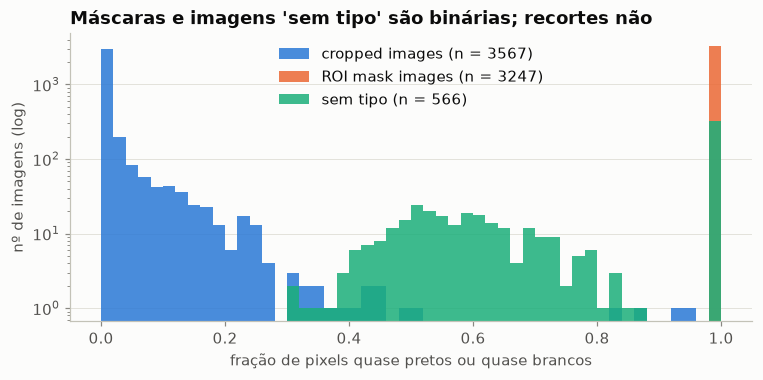

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 51)
for tipo, cor in [("cropped images", AZUL), ("ROI mask images", LARANJA), ("sem tipo", VERDE_AGUA)]:
    v = qualidade.loc[qualidade["tipo_rotulado"] == tipo, "fracao_binaria"]
    ax.hist(v, bins=bins, color=cor, alpha=0.85, label=f"{tipo} (n = {len(v)})")
ax.set_yscale("log")
ax.set_xlabel("fração de pixels quase pretos ou quase brancos")
ax.set_ylabel("nº de imagens (log)")
ax.set_title("Máscaras e imagens 'sem tipo' são binárias; recortes não")
ax.legend(loc="upper center")
salvar(fig, "08_qualidade_fracao_binaria")

In [5]:
LIMIAR_BINARIA = 0.95
sem_tipo = qualidade[qualidade["tipo_imagem"].isna()].copy()
sem_tipo["tipo_inferido"] = np.where(sem_tipo["fracao_binaria"] >= LIMIAR_BINARIA, "ROI mask images", "outro")
sem_tipo["chave"] = sem_tipo["case_id"].str.replace(".dcm", "", regex=False)

# a chave "P_00562_LEFT_CC_2" é o final do case_roi da lesão ("Calc-Test_P_00562_LEFT_CC_2")
sem_mascara = ligado.loc[ligado["caminho_mascara"].isna(), "case_roi"].drop_duplicates()
sufixo = sem_mascara.str.extract(r"(P_\d+_(?:LEFT|RIGHT)_(?:CC|MLO)_\d+)$")[0]
candidatos = pd.Series(sem_mascara.values, index=sufixo.values)
unicos = candidatos[~candidatos.index.duplicated(keep=False)]
sem_tipo["case_roi"] = sem_tipo["chave"].map(unicos)

resumo_sem_tipo = pd.Series({
    "imagens sem tipo": len(sem_tipo),
    "inferidas como máscara (conteúdo binário)": (sem_tipo["tipo_inferido"] == "ROI mask images").sum(),
    "ligadas a exatamente 1 lesão sem máscara": sem_tipo["case_roi"].notna().sum(),
    "recortes rotulados com conteúdo binário (trocados?)":
        ((qualidade["tipo_imagem"] == "cropped images") & (qualidade["fracao_binaria"] >= LIMIAR_BINARIA)).sum(),
    "máscaras rotuladas com conteúdo NÃO binário (trocadas?)":
        ((qualidade["tipo_imagem"] == "ROI mask images") & (qualidade["fracao_binaria"] < LIMIAR_BINARIA)).sum(),
})
resumo_sem_tipo.to_frame("n")

,n
imagens sem tipo,566
inferidas como máscara (conteúdo binário),320
ligadas a exatamente 1 lesão sem máscara,320
recortes rotulados com conteúdo binário (trocados?),1
máscaras rotuladas com conteúdo NÃO binário (trocadas?),0


In [6]:
# recupera as máscaras: tipo inferido pelo conteúdo + caso inferido pelo identificador
recuperadas = sem_tipo.dropna(subset=["case_roi"]).query("tipo_inferido == 'ROI mask images'")
mapa_recuperado = recuperadas.set_index("case_roi")["caminho"]
ligado["mascara_recuperada"] = ligado["caminho_mascara"].isna() & ligado["case_roi"].isin(mapa_recuperado.index)
ligado["caminho_mascara"] = ligado["caminho_mascara"].fillna(ligado["case_roi"].map(mapa_recuperado))
print(f"Máscaras recuperadas: {ligado['mascara_recuperada'].sum()} lesões")
print(f"Lesões com máscara: {ligado['caminho_mascara'].notna().mean():.1%} (antes: {cobertura.loc['mascara', '%']:.1f}%)")

Máscaras recuperadas: 320 lesões
Lesões com máscara: 100.0% (antes: 91.0%)


As imagens sem tipo que **não** são binárias têm o perfil de uma mamografia completa: muito fundo preto, com fração
binária entre 0,3 e 0,9. O identificador delas também termina em `_N`, mas a mamografia completa é do caso
**sem** o número da lesão. Então o caso é procurado tirando o sufixo.

In [7]:
fulls = sem_tipo.query("tipo_inferido == 'outro'").copy()
fulls["chave_full"] = fulls["chave"].str.replace(r"_\d+$", "", regex=True)
sem_full = ligado.loc[ligado["caminho_full"].isna(), "case_full"].drop_duplicates()
sufixo_full = sem_full.str.extract(r"(P_\d+_(?:LEFT|RIGHT)_(?:CC|MLO))$")[0]
cand_full = pd.Series(sem_full.values, index=sufixo_full.values)
cand_full = cand_full[~cand_full.index.duplicated(keep=False)]
fulls["case_full"] = fulls["chave_full"].map(cand_full)
mapa_full = fulls.dropna(subset=["case_full"]).drop_duplicates("case_full").set_index("case_full")["caminho"]

ligado["full_recuperada"] = ligado["caminho_full"].isna() & ligado["case_full"].isin(mapa_full.index)
ligado["caminho_full"] = ligado["caminho_full"].fillna(ligado["case_full"].map(mapa_full))
print(f"Imagens não binárias sem tipo: {len(fulls)} | ligadas a um caso sem mamografia: {fulls['case_full'].notna().sum()}")
print(f"Lesões com mamografia completa: {ligado['caminho_full'].notna().mean():.1%} (antes: {cobertura.loc['full', '%']:.1f}%)")

Imagens não binárias sem tipo: 246 | ligadas a um caso sem mamografia: 246
Lesões com mamografia completa: 100.0% (antes: 92.1%)


## 2. Validação visual

Para algumas lesões: a mamografia completa com o **contorno da máscara** desenhado, e o recorte. Se a ligação estiver
certa, o contorno cai sobre a lesão, e o recorte mostra a mesma região.

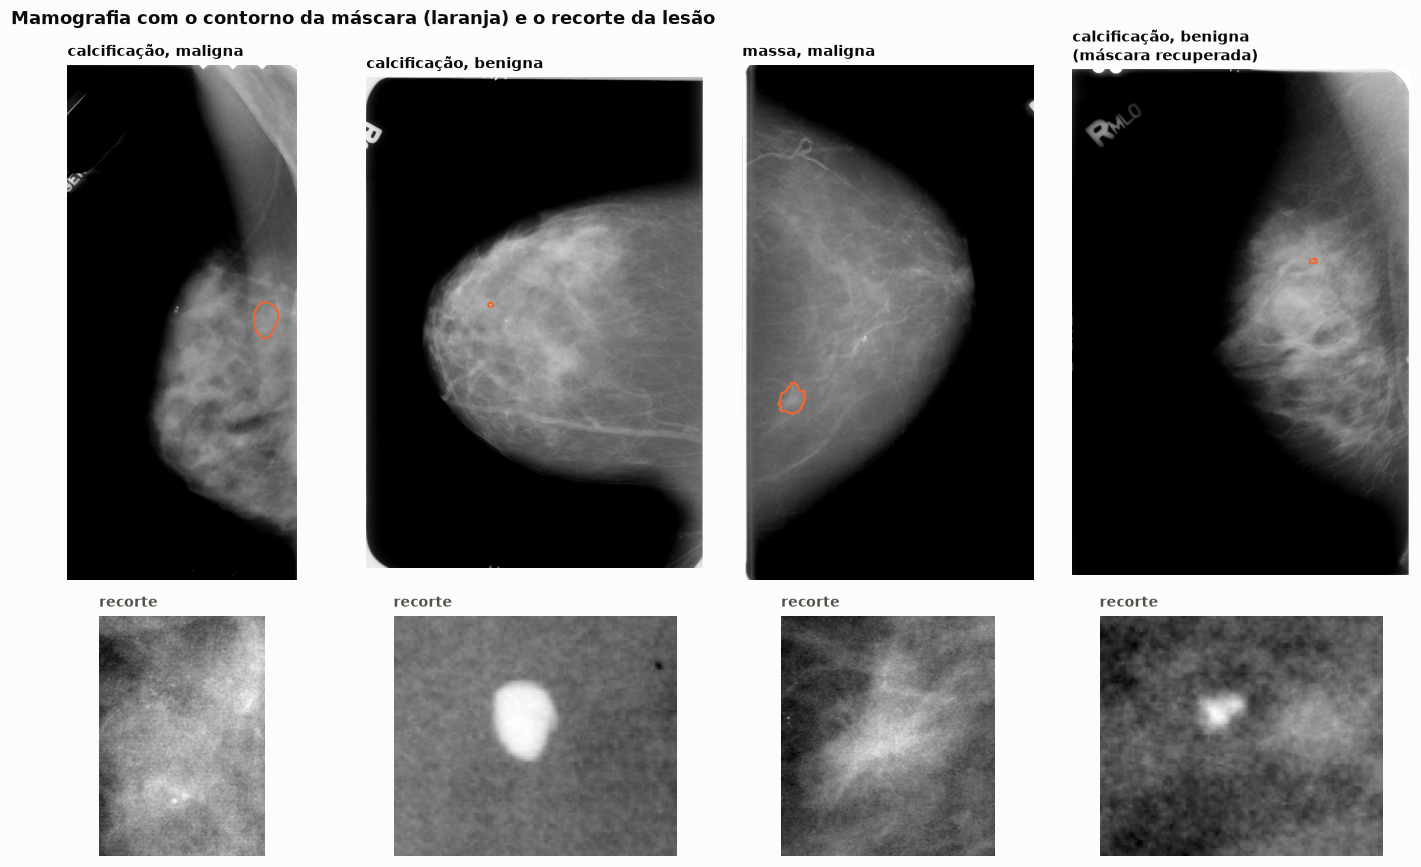

In [8]:
def contorno_mascara(caminho_mascara, forma_full):
    m = le_cinza(caminho_mascara)
    if m.shape != forma_full:
        m = cv2.resize(m, (forma_full[1], forma_full[0]), interpolation=cv2.INTER_NEAREST)
    contornos, _ = cv2.findContours((m > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return contornos

completos = ligado.dropna(subset=["caminho_full", "caminho_recorte", "caminho_mascara"])
amostra = pd.concat([
    completos.query("abnormality_type == 'calcification' and maligno").sample(1, random_state=7),
    completos.query("abnormality_type == 'calcification' and not maligno").sample(1, random_state=7),
    completos.query("abnormality_type == 'mass' and maligno").sample(1, random_state=7),
    completos.query("mascara_recuperada").sample(1, random_state=7),
])

fig, axes = plt.subplots(2, len(amostra), figsize=(13, 8), gridspec_kw={"height_ratios": [3, 1.4]})
for j, (_, r) in enumerate(amostra.iterrows()):
    full = le_cinza(r["caminho_full"])
    contornos = contorno_mascara(r["caminho_mascara"], full.shape)
    axes[0, j].imshow(full, cmap="gray")
    for c in contornos:
        axes[0, j].plot(c[:, 0, 0], c[:, 0, 1], color=LARANJA, lw=1.2)
    tipo = "calcificação" if r["abnormality_type"] == "calcification" else "massa"
    extra = "\n(máscara recuperada)" if r["mascara_recuperada"] else ""
    axes[0, j].set_title(f"{tipo}, {'maligna' if r['maligno'] else 'benigna'}{extra}", fontsize=10)
    axes[1, j].imshow(le_cinza(r["caminho_recorte"]), cmap="gray")
    axes[1, j].set_title("recorte", fontsize=9, color=estilo.TINTA_SECUNDARIA)
    for a in axes[:, j]:
        a.axis("off")
fig.suptitle("Mamografia com o contorno da máscara (laranja) e o recorte da lesão", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "09_validacao_visual")

## 3. Processamento digital de imagens: microcalcificações

Microcalcificações são pontos pequenos e muito brilhantes. O pipeline (em `src/images/calcificacoes.py`) é aplicado
ao **recorte** de cada lesão de calcificação:

1. **Máscara de tecido:** descarta o fundo preto e erode a borda da mama, porque a transição pele/fundo gera
   falsos pontos;
2. **CLAHE** (equalização adaptativa) + suavização leve: padroniza o contraste entre scanners diferentes e reduz o
   ruído do JPEG;
3. **Top-hat branco** com disco de raio {calc_pdi.RAIO_TOPHAT} px: realça estruturas claras menores que o disco e
   remove o fundo de variação lenta;
4. **Limiar robusto** dentro do tecido: mediana + {calc_pdi.K_MAD}·MAD, com **piso absoluto**. Sem o piso, um
   recorte sem calcificação ainda "acharia" pontos no ruído. Por fim, ficam só os componentes entre
   {calc_pdi.AREA_MIN} e {calc_pdi.AREA_MAX} px.

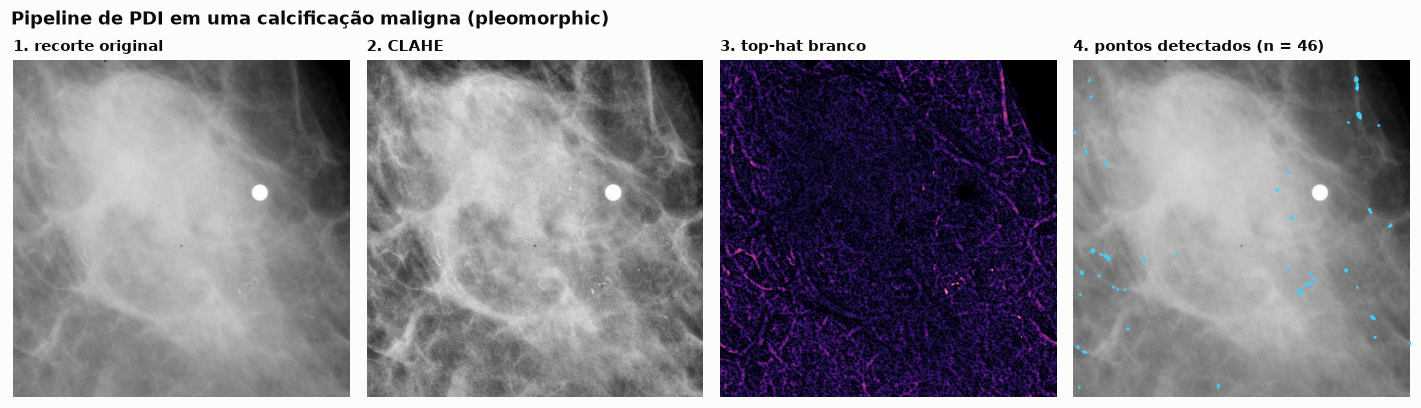

In [9]:
exemplo = ligado.query("abnormality_type == 'calcification' and maligno").dropna(subset=["caminho_recorte"])
r = exemplo[exemplo["calc_type"] == "PLEOMORPHIC"].sample(1, random_state=11).iloc[0]
img = le_cinza(r["caminho_recorte"])
tecido = calc_pdi.mascara_tecido(img)
tophat, pontos = calc_pdi.segmenta_calcificacoes(img)

etapas = [(img, "1. recorte original"), (calc_pdi.realce(img), "2. CLAHE"),
          (tophat, "3. top-hat branco"), (img, f"4. pontos detectados (n = {int(pontos.any() and len(np.unique(cv2.connectedComponents(pontos.astype(np.uint8))[1])) - 1)})")]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, (im, titulo) in zip(axes, etapas):
    ax.imshow(im, cmap="magma" if "top-hat" in titulo else "gray")
    ax.set_title(titulo, fontsize=10)
    ax.axis("off")
yx = np.argwhere(pontos)
axes[3].scatter(yx[:, 1], yx[:, 0], s=1.5, color="#3fd0ff", linewidths=0)
fig.suptitle(f"Pipeline de PDI em uma calcificação maligna ({r['calc_type'].lower()})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "10_pipeline_pdi")

### 3.1 Extração para todas as calcificações

Uma linha por **recorte de lesão** (cerca de 0,08 s por recorte). O resultado fica em cache em `data/processed/`.

In [10]:
cache_feat = config.PROCESSED / "cbis_caracteristicas_calcificacoes.csv"
calcs = ligado.query("abnormality_type == 'calcification'").dropna(subset=["caminho_recorte"])
if cache_feat.exists():
    feat = pd.read_csv(cache_feat)
else:
    linhas = [extrai_caracteristicas(le_cinza(c)) for c in calcs["caminho_recorte"]]
    feat = pd.DataFrame(linhas)
    feat.insert(0, "case_roi", calcs["case_roi"].values)
    config.PROCESSED.mkdir(parents=True, exist_ok=True)
    feat.to_csv(cache_feat, index=False)

dados = calcs[["case_roi", "patient_id", "origem_split", "breast_density", "calc_type", "maligno"]].merge(feat, on="case_roi")
CARACTERISTICAS = ["altura", "largura", "fracao_tecido", "intensidade_media", "contraste", "n_pontos",
                   "densidade_pontos_por_10k_px", "area_media_ponto", "area_cv_ponto",
                   "excentricidade_media", "dist_vizinho_media", "tophat_p99"]
print(dados.shape, "| recortes sem nenhum ponto detectado:", f"{(dados['n_pontos'] == 0).mean():.0%}")
dados[CARACTERISTICAS].describe().T[["mean", "50%", "min", "max"]]

(1871, 18) | recortes sem nenhum ponto detectado: 27%


,mean,50%,min,max
altura,462.414,313.000,73.000,"3,841.000"
largura,471.379,329.000,68.000,"2,893.000"
fracao_tecido,0.871,0.923,0.000,0.999
intensidade_media,119.871,119.089,36.414,216.531
contraste,35.564,34.765,0.000,89.521
n_pontos,12.496,2.000,0.000,935.000
densidade_pontos_por_10k_px,0.442,0.202,0.000,19.055
area_media_ponto,17.105,12.333,0.000,247.000
area_cv_ponto,0.619,0.628,0.000,2.409
excentricidade_media,0.717,0.735,0.000,0.994


## 4. Características × malignidade

Para cada característica: mediana em lesões benignas e malignas, teste de **Mann-Whitney** (não paramétrico) e a
**AUC univariada** (0,5 = não separa; 1 = separa perfeitamente; abaixo de 0,5 = maior em benignas). A AUC é um tamanho
de efeito fácil de ler.

In [11]:
def compara(var):
    v = dados[[var, "maligno"]].dropna()
    mal, ben = v.loc[v["maligno"], var], v.loc[~v["maligno"], var]
    return {"característica": var, "mediana benigna": ben.median(), "mediana maligna": mal.median(),
            "p (Mann-Whitney)": mannwhitneyu(mal, ben).pvalue,
            "AUC": roc_auc_score(v["maligno"], v[var])}

malignidade = pd.DataFrame([compara(v) for v in CARACTERISTICAS]).set_index("característica")
malignidade["|AUC − 0,5|"] = (malignidade["AUC"] - 0.5).abs()
malignidade.sort_values("|AUC − 0,5|", ascending=False)

,mediana benigna,mediana maligna,p (Mann-Whitney),AUC,"|AUC − 0,5|"
característica,,,,,
altura,257.000,473.000,0.000,0.709,0.209
largura,258.000,489.000,0.000,0.703,0.203
n_pontos,1.000,6.000,0.000,0.677,0.177
intensidade_media,112.027,131.356,0.000,0.658,0.158
tophat_p99,56.000,43.000,0.000,0.348,0.152
area_cv_ponto,0.527,0.748,0.000,0.638,0.138
fracao_tecido,0.909,0.947,0.000,0.623,0.123
dist_vizinho_media,45.702,60.711,0.000,0.598,0.098
excentricidade_media,0.754,0.717,0.000,0.415,0.085


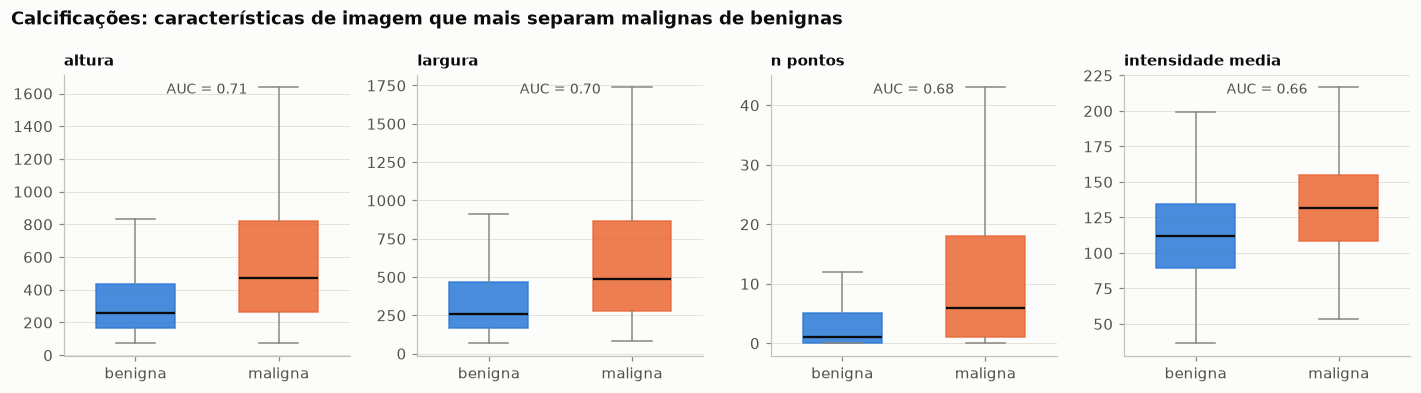

In [12]:
top = malignidade.sort_values("|AUC − 0,5|", ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, var in zip(axes, top):
    grupos = [dados.loc[~dados["maligno"], var].dropna(), dados.loc[dados["maligno"], var].dropna()]
    bp = ax.boxplot(grupos, tick_labels=["benigna", "maligna"], showfliers=False, widths=0.55, patch_artist=True,
                    medianprops=dict(color=estilo.TINTA, lw=1.5))
    for caixa, cor in zip(bp["boxes"], [AZUL, LARANJA]):
        caixa.set(facecolor=cor, edgecolor=cor, alpha=0.85)
    for parte in ["whiskers", "caps"]:
        for linha in bp[parte]:
            linha.set(color=estilo.TINTA_SUAVE)
    ax.set_title(var.replace("_", " "), fontsize=10)
    ax.text(0.5, 0.97, f"AUC = {malignidade.loc[var, 'AUC']:.2f}", transform=ax.transAxes, ha="center", va="top",
            color=estilo.TINTA_SECUNDARIA, fontsize=9)
fig.suptitle("Calcificações: características de imagem que mais separam malignas de benignas",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "11_caracteristicas_malignidade")

## 5. Características × densidade mamária

Esta é a ponte com a pergunta do trabalho. Se a **aparência das imagens** e o que o PDI consegue **detectar** mudam
com a densidade, um modelo treinado numa base com certa distribuição de densidades pode se comportar diferente numa
população com outra distribuição. Teste de **Kruskal-Wallis** entre as 4 categorias de densidade.

In [13]:
por_densidade = dados.dropna(subset=["breast_density"])
resultado = []
for var in ["intensidade_media", "contraste", "n_pontos", "tophat_p99"]:
    grupos = [g[var].dropna() for _, g in por_densidade.groupby("breast_density")]
    medianas = por_densidade.groupby("breast_density")[var].median()
    resultado.append({"característica": var, **{f"densidade {int(k)}": v for k, v in medianas.items()},
                      "p (Kruskal-Wallis)": kruskal(*grupos).pvalue})
densidade_tab = pd.DataFrame(resultado).set_index("característica")
densidade_tab

,densidade 1,densidade 2,densidade 3,densidade 4,p (Kruskal-Wallis)
característica,,,,,
intensidade_media,91.564,110.944,124.128,139.224,0.000
contraste,29.090,33.137,36.308,38.240,0.000
n_pontos,2.000,2.000,2.000,3.000,0.018
tophat_p99,63.000,55.000,51.000,44.000,0.000


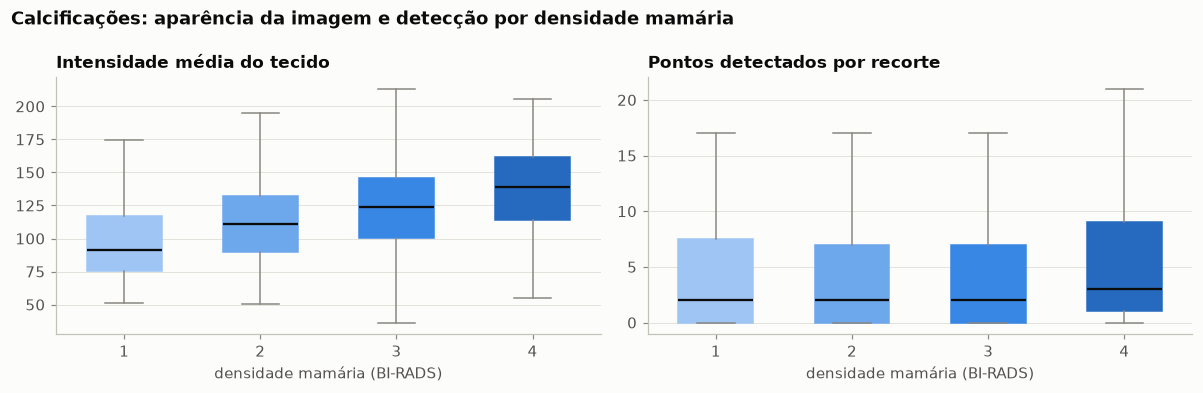

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, var, titulo in [(axes[0], "intensidade_media", "Intensidade média do tecido"),
                        (axes[1], "n_pontos", "Pontos detectados por recorte")]:
    grupos = [g[var].dropna() for _, g in por_densidade.groupby("breast_density")]
    bp = ax.boxplot(grupos, tick_labels=["1", "2", "3", "4"], showfliers=False, widths=0.55, patch_artist=True,
                    medianprops=dict(color=estilo.TINTA, lw=1.5))
    for caixa, cor in zip(bp["boxes"], estilo.SEQUENCIAL_AZUL[1:5]):
        caixa.set(facecolor=cor, edgecolor=cor)
    for parte in ["whiskers", "caps"]:
        for linha in bp[parte]:
            linha.set(color=estilo.TINTA_SUAVE)
    ax.set_xlabel("densidade mamária (BI-RADS)")
    ax.set_title(titulo, fontsize=11)
fig.suptitle("Calcificações: aparência da imagem e detecção por densidade mamária", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "12_caracteristicas_densidade")

## 6. Modelo simples e viés

Um **Random Forest** prevê malignidade **só com as características de imagem** (sem BI-RADS, que já é a suspeita do
radiologista). Usamos a divisão **oficial** do CBIS-DDSM em treino e teste. O objetivo não é um modelo competitivo,
e sim **observar o comportamento** do modelo:

- **por densidade mamária:** o desempenho é igual em mamas mais e menos densas?
- **por prevalência:** o que acontece com o valor preditivo positivo (VPP) quando o modelo sai de uma base com ~40%
  de câncer e vai para uma população como a do SUS, com cerca de 1,7 caso por 100 mamografias (ver notebook 01)?

In [15]:
treino = dados[dados["origem_split"] == "train"]
teste = dados[dados["origem_split"] == "test"]
print("Pacientes em treino E teste:", len(set(treino["patient_id"]) & set(teste["patient_id"])))

X_treino, X_teste = treino[CARACTERISTICAS].fillna(-1), teste[CARACTERISTICAS].fillna(-1)
modelo = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1)
modelo.fit(X_treino, treino["maligno"])
teste = teste.assign(prob=modelo.predict_proba(X_teste)[:, 1])
auc_teste = roc_auc_score(teste["maligno"], teste["prob"])
print(f"AUC no teste: {auc_teste:.3f}  (n = {len(teste)}, {teste['maligno'].mean():.0%} malignas)")

# previsões do teste, usadas no notebook 04 para reponderar pela composição do Brasil
teste[["case_roi", "patient_id", "breast_density", "maligno", "prob"]].to_csv(
    config.PROCESSED / "cbis_predicoes_teste_calcificacoes.csv", index=False)

importancia = pd.Series(modelo.feature_importances_, index=CARACTERISTICAS).sort_values(ascending=False)
importancia.round(3).to_frame("importância")

Pacientes em treino E teste: 0


AUC no teste: 0.741  (n = 326, 40% malignas)


,importância
altura,0.146
largura,0.130
intensidade_media,0.120
fracao_tecido,0.092
tophat_p99,0.079
contraste,0.079
dist_vizinho_media,0.074
area_media_ponto,0.063
excentricidade_media,0.063
n_pontos,0.057


In [16]:
def auc_por_grupo(df, col):
    linhas = []
    for valor, g in df.groupby(col):
        if g["maligno"].nunique() == 2 and len(g) >= 30:
            linhas.append({col: valor, "n": len(g), "% malignas": 100 * g["maligno"].mean(),
                           "AUC": roc_auc_score(g["maligno"], g["prob"])})
    return pd.DataFrame(linhas).set_index(col)

auc_densidade = auc_por_grupo(teste.dropna(subset=["breast_density"]).astype({"breast_density": int}), "breast_density")
auc_densidade

,n,% malignas,AUC
breast_density,,,
2,115,32.174,0.850
3,115,44.348,0.707
4,70,50.000,0.522


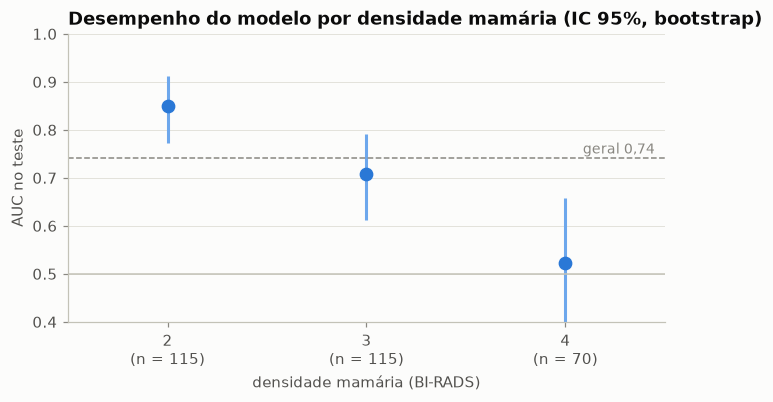

In [17]:
# bootstrap: intervalo de 95% da AUC em cada densidade (o teste é pequeno)
rng = np.random.default_rng(0)
ics = {}
for d, g in teste.dropna(subset=["breast_density"]).groupby("breast_density"):
    aucs = []
    for _ in range(500):
        b = g.sample(len(g), replace=True, random_state=int(rng.integers(1e9)))
        if b["maligno"].nunique() == 2:
            aucs.append(roc_auc_score(b["maligno"], b["prob"]))
    ics[int(d)] = np.percentile(aucs, [2.5, 97.5])
auc_densidade["IC95% inf"] = [ics[d][0] for d in auc_densidade.index]
auc_densidade["IC95% sup"] = [ics[d][1] for d in auc_densidade.index]

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(auc_densidade))
ax.errorbar(x, auc_densidade["AUC"],
            yerr=[auc_densidade["AUC"] - auc_densidade["IC95% inf"], auc_densidade["IC95% sup"] - auc_densidade["AUC"]],
            fmt="o", color=AZUL, ecolor=estilo.SEQUENCIAL_AZUL[2], elinewidth=2, capsize=0, markersize=8)
ax.axhline(auc_teste, color=estilo.TINTA_SUAVE, ls="--", lw=1)
ax.text(len(x) - 0.55, auc_teste + 0.01, f"geral {auc_teste:.2f}".replace(".", ","), color=estilo.TINTA_SUAVE,
        fontsize=9, ha="right")
ax.axhline(0.5, color=estilo.EIXO, lw=1)
ax.set_xticks(x, [f"{d}\n(n = {n})" for d, n in zip(auc_densidade.index, auc_densidade["n"])])
ax.set_xlabel("densidade mamária (BI-RADS)")
ax.set_ylabel("AUC no teste")
ax.set_ylim(0.4, 1.0)
ax.set_xlim(-0.5, len(x) - 0.5)
ax.set_title("Desempenho do modelo por densidade mamária (IC 95%, bootstrap)")
salvar(fig, "13_auc_por_densidade")

### 6.1 Mudança de prevalência: do CBIS-DDSM para o SUS

Sensibilidade e especificidade são propriedades do modelo e não dependem de quantos casos são câncer. Já o **VPP**
(de cada alerta do modelo, quantos são câncer de verdade) depende da prevalência:

$$\text{VPP} = \frac{\text{sens} \cdot p}{\text{sens} \cdot p + (1 - \text{espec}) \cdot (1 - p)}$$

Fixamos o limiar que dá **85% de sensibilidade** no treino (validação cruzada) e aplicamos no teste.

In [18]:
from sklearn.model_selection import GroupKFold, cross_val_predict

oof = cross_val_predict(modelo, X_treino, treino["maligno"], groups=treino["patient_id"],
                        cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
fpr, tpr, limiares = roc_curve(treino["maligno"], oof)
limiar = limiares[np.argmax(tpr >= 0.85)]

pred = teste["prob"] >= limiar
sens = (pred & teste["maligno"]).sum() / teste["maligno"].sum()
espec = (~pred & ~teste["maligno"]).sum() / (~teste["maligno"]).sum()

def vpp(p):
    return sens * p / (sens * p + (1 - espec) * (1 - p))

p_cbis = teste["maligno"].mean()
p_sus = 0.017
cenarios = pd.DataFrame({
    "prevalência": [p_cbis, p_sus],
    "VPP": [vpp(p_cbis), vpp(p_sus)],
    "falsos positivos por câncer detectado": [(1 - vpp(p_cbis)) / vpp(p_cbis), (1 - vpp(p_sus)) / vpp(p_sus)],
}, index=["CBIS-DDSM (teste)", "SUS (≈ casos ÷ mamografias)"])
print(f"Limiar = {limiar:.3f} | sensibilidade no teste = {sens:.1%} | especificidade = {espec:.1%}")
cenarios

Limiar = 0.364 | sensibilidade no teste = 88.4% | especificidade = 40.1%


,prevalência,VPP,falsos positivos por câncer detectado
CBIS-DDSM (teste),0.396,0.491,1.035
SUS (≈ casos ÷ mamografias),0.017,0.025,39.193


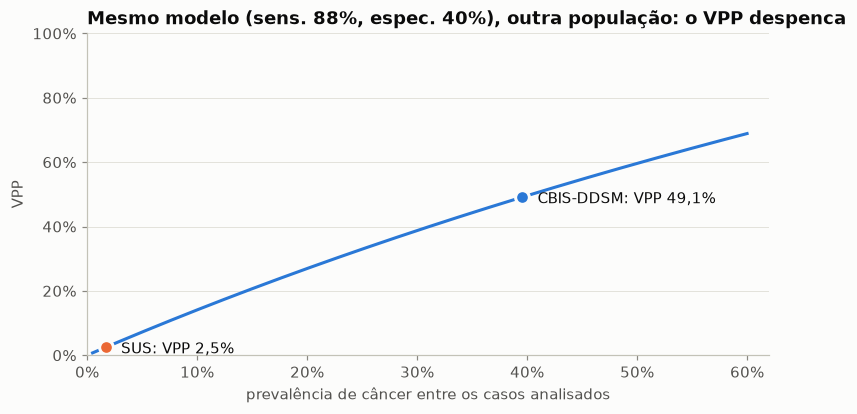

In [19]:
p = np.linspace(0.005, 0.6, 300)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(100 * p, 100 * vpp(p), color=AZUL)
for prev, rotulo, cor in [(p_cbis, "CBIS-DDSM", AZUL), (p_sus, "SUS", LARANJA)]:
    ax.plot(100 * prev, 100 * vpp(prev), "o", color=cor, markersize=9, markeredgecolor=estilo.FUNDO, markeredgewidth=2)
    ax.annotate(f"{rotulo}: VPP {100 * vpp(prev):.1f}%".replace(".", ","), (100 * prev, 100 * vpp(prev)), xytext=(10, -4),
                textcoords="offset points", color=estilo.TINTA, fontsize=10)
ax.set_xlabel("prevalência de câncer entre os casos analisados")
ax.set_ylabel("VPP")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.set_xlim(0, 62)
ax.set_title(f"Mesmo modelo (sens. {sens:.0%}, espec. {espec:.0%}), outra população: o VPP despenca")
salvar(fig, "14_vpp_prevalencia")

### 6.2 O mesmo modelo em cada região do Brasil

A prevalência também muda **dentro** do Brasil. Para cada região, usamos o mesmo indicador do SUS acima: casos
novos estimados (INCA 2023, soma das UFs) ÷ mamografias no SUS (SIA 2022, rastreamento + diagnóstica). Com a
sensibilidade e a especificidade fixas, calculamos o VPP e, com o volume de rastreamentos de 2022, quantos alertas
o modelo daria por ano em cada região.

**Cuidado:** o numerador conta todos os casos, inclusive os diagnosticados fora do SUS, e o denominador só os
exames do SUS. Onde há mais planos de saúde (Sudeste, Sul, DF), a prevalência fica **superestimada**. Os valores
servem para comparar a ordem de grandeza entre regiões, não como estimativa exata.

In [20]:
D = config.ROOT / "dashboards" / "dados"
dim = pd.read_csv(D / "dim_localidade.csv", encoding="utf-8-sig")
fato22 = pd.read_csv(D / "fato_uf_ano.csv", encoding="utf-8-sig").query("ano == 2022").merge(dim, on="localidade")
casos_uf = pd.read_csv(D / "fato_incidencia_uf.csv", encoding="utf-8-sig").merge(dim, on="localidade")

reg = fato22.groupby("regiao")[["mamografias_rastreamento", "mamografias_diagnosticas"]].sum()
reg["casos_estimados"] = casos_uf.groupby("regiao")["casos_estimados"].sum()
reg.loc["Brasil"] = reg.sum()
reg["prevalencia"] = reg["casos_estimados"] / (reg["mamografias_rastreamento"] + reg["mamografias_diagnosticas"])
reg["VPP"] = vpp(reg["prevalencia"])
reg["falsos positivos por câncer detectado"] = (1 - reg["VPP"]) / reg["VPP"]
n = reg["mamografias_rastreamento"]
reg["cânceres detectados/ano"] = n * reg["prevalencia"] * sens
reg["falsos positivos/ano"] = n * (1 - reg["prevalencia"]) * (1 - espec)

ORDEM = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul", "Brasil"]
vpp_regiao = reg.reindex(ORDEM)
cbis_linha = pd.DataFrame({"prevalencia": [p_cbis], "VPP": [vpp(p_cbis)],
                           "falsos positivos por câncer detectado": [(1 - vpp(p_cbis)) / vpp(p_cbis)]},
                          index=["CBIS-DDSM (teste)"])
pd.concat([vpp_regiao, cbis_linha]).to_csv(config.PROCESSED / "vpp_regiao.csv", index_label="regiao")  # usado pelo painel
vpp_regiao[["prevalencia", "VPP", "falsos positivos por câncer detectado",
            "cânceres detectados/ano", "falsos positivos/ano"]].style.format({
    "prevalencia": "{:.2%}", "VPP": "{:.1%}", "falsos positivos por câncer detectado": "{:.0f}",
    "cânceres detectados/ano": "{:,.0f}", "falsos positivos/ano": "{:,.0f}"})

,prevalencia,VPP,falsos positivos por câncer detectado,cânceres detectados/ano,falsos positivos/ano
regiao,,,,,
Norte,1.74%,2.6%,38,"1,997","76,238"
Nordeste,1.66%,2.4%,40,"13,156","529,449"
Centro-Oeste,2.34%,3.4%,28,"4,106","116,130"
Sudeste,1.84%,2.7%,36,"30,747","1,113,752"
Sul,1.38%,2.0%,48,"9,083","439,713"
Brasil,1.73%,2.5%,38,"59,144","2,275,244"


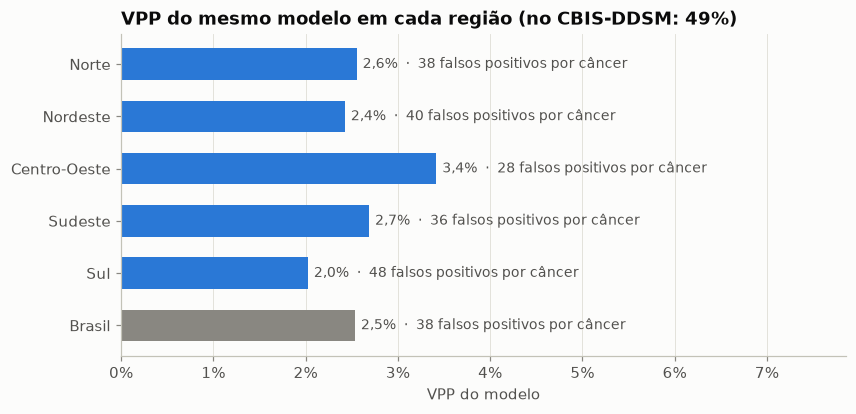

In [21]:
r = vpp_regiao.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
cores = [estilo.TINTA_SUAVE if regiao == "Brasil" else AZUL for regiao in r.index]
barras = ax.barh(r.index, 100 * r["VPP"], color=cores, height=0.6)
ax.bar_label(barras, padding=4, fontsize=9, color=estilo.TINTA_SECUNDARIA,
             labels=[f"{100 * v:.1f}%  ·  {fp:.0f} falsos positivos por câncer".replace(".", ",")
                     for v, fp in zip(r["VPP"], r["falsos positivos por câncer detectado"])])
ax.set_xlim(0, 100 * r["VPP"].max() * 2.3)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("VPP do modelo")
ax.set_title(f"VPP do mesmo modelo em cada região (no CBIS-DDSM: {100 * vpp(p_cbis):.0f}%)")
salvar(fig, "25_vpp_por_regiao")

**Leitura:** em todas as regiões o VPP fica entre 2% e 3,4%, contra cerca de 49% no CBIS-DDSM. A diferença
**entre** as regiões é pequena perto da queda que acontece ao sair da base para qualquer população real: o
problema principal é a prevalência da base, não a região. Mesmo assim, a mesma regra de decisão rende de 28
falsos positivos por câncer (Centro-Oeste, maior prevalência estimada) a 48 (Sul, menor). Em números absolutos,
com o volume de rastreamento de 2022, o modelo geraria cerca de **2,3 milhões de alertas falsos por ano** no país,
quase metade no Sudeste, que é onde se fazem mais exames.

## 7. Conclusões

**Qualidade dos dados**

- O `dicom_info.csv` da versão Kaggle tem **566 imagens sem tipo**. Pelo **conteúdo** (fração de pixels binários) e
  pelo identificador, **todas foram recuperadas**: 320 máscaras e 246 mamografias completas. A cobertura passou de
  91% para **100%** (máscaras) e de 92% para **100%** (mamografias). A validação visual confirma que uma máscara
  recuperada cai sobre a lesão.
- Só **1 recorte** tem conteúdo binário (provável troca recorte ↔ máscara). Nesta versão, o problema de troca é
  raro.

**Imagem × malignidade**

- As calcificações malignas têm **mais pontos detectados** (mediana 6 × 1) e **maior heterogeneidade de tamanho**
  dos pontos, o que é coerente com a descrição clínica de calcificações pleomórficas.
- Porém, as características que mais separam são **altura e largura do recorte** (AUC ≈ 0,71). Elas medem a
  extensão da lesão como foi **anotada pelo radiologista**, e não algo que o algoritmo descobriu. É um aviso
  importante: parte do "sinal" de bases anotadas vem da própria anotação.

**Densidade mamária: o achado principal para a pergunta do trabalho**

- A aparência da imagem muda sistematicamente com a densidade: a intensidade média do tecido sobe de ~92
  (densidade 1) para ~139 (densidade 4), e o contraste local dos pontos (`tophat_p99`) cai.
- O **mesmo modelo** tem AUC de **0,85 em mamas de densidade 2**, mas **0,52 (praticamente o acaso) em densidade 4**.
  O desempenho geral (0,74) **esconde** essa diferença.
- Portanto, a **distribuição de densidade da população** onde o modelo é usado importa. Se as brasileiras atendidas
  no SUS tiverem mais mamas densas do que o CBIS-DDSM (o que é plausível entre mulheres mais jovens, e 27% do
  rastreamento do SUS é feito entre 40 e 49 anos), o desempenho real será pior do que o medido na base. Essa
  distribuição não está nos dados coletados; é a principal lacuna para o próximo passo (SISCAN).

**Prevalência**

- Com sensibilidade de 88% e especificidade de 40%, o VPP é de **49% no CBIS-DDSM** e cai para **cerca de 2,5% na
  prevalência estimada do SUS**: cerca de **39 falsos positivos para cada câncer detectado**. Métricas medidas na
  base não se transferem para o rastreamento real.
- **Por região (seção 6.2):** o VPP fica entre 2% e 4% em todas as regiões. A variação entre regiões é pequena
  perto da queda em relação à base: o problema principal é a prevalência do CBIS-DDSM, e não a região.

**Limitações**

- O PDI é simples e explicável, não o estado da arte: detecta parte dos vasos e estruturas fibrosas como pontos e
  perde calcificações muito tênues (27% dos recortes ficaram sem nenhum ponto).
- As imagens do Kaggle são **JPEG de 8 bits**, convertidas do DICOM de 16 bits; parte do contraste fino se perde.
- O conjunto de teste é pequeno por densidade (70 a 115 lesões), por isso os intervalos de confiança largos. A
  densidade 1 não aparece no teste com tamanho suficiente.
- O modelo usa só calcificações e só características manuais. Um modelo profundo (CNN) poderia ter outro padrão de
  erro, mas a lógica da análise (avaliar por subgrupo e por prevalência) continua valendo.